#1.Import Libraries:

In [42]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

#2. Load Dataset:

In [43]:
file_path = '/content/Gold_Price_Prediction_8000_Rows.xlsx'

data = pd.read_excel(file_path)

data.head()

,Date,Open,High,Low,Close,Volume
0,1996-03-21,452.42,453.39,446.54,450.00,31146
1,1996-03-22,453.04,455.34,441.37,445.34,45028
2,1996-03-25,444.21,453.77,442.05,450.56,30095
3,1996-03-26,451.05,460.18,450.50,455.90,29573
4,1996-03-27,451.23,455.28,440.53,445.91,16111


#3. Data Inspection:

In [44]:
data.shape

(8000, 6)

In [45]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    8000 non-null   datetime64[ns]
 1   Open    8000 non-null   float64       
 2   High    8000 non-null   float64       
 3   Low     8000 non-null   float64       
 4   Close   8000 non-null   float64       
 5   Volume  8000 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 375.1 KB


In [46]:
data.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Volume,0


#4. Select Close Price Column:

In [47]:
if 'close' in data.columns:
    data.rename(columns={'close': 'Close'}, inplace=True)

df = data[['Close']].dropna().copy()

print('Dataset shape:', df.shape)

Dataset shape: (8000, 1)


#5. Feature Engineering:

In [48]:
df['Returns'] = df['Close'].pct_change()

df['Lag_1'] = df['Returns'].shift(1)

df['Lag_2'] = df['Returns'].shift(2)

df['SMA_7'] = df['Close'].rolling(window=7).mean() / df['Close']

df['Volatility'] = df['Returns'].rolling(window=7).std()

#Explanation:
#Feature	#Purpose
*Returns	Price percentage change
*Lag_1	Previous day's return
*Lag_2	Two days previous return
*SMA_7	7-day moving average ratio
*Volatility	7-day price return volatility

#6. Remove Missing Values:

In [49]:
df.dropna(inplace=True)

df.head()

,Close,Returns,Lag_1,Lag_2,SMA_7,Volatility
7,444.88,0.001260,0.007414,-0.010899,1.004431,0.013061
8,446.93,0.004608,0.001260,0.007414,1.000332,0.012598
9,444.52,-0.005392,0.004608,0.001260,1.003815,0.011704
10,451.30,0.015252,-0.005392,0.004608,0.987278,0.012417
11,456.45,0.011411,0.015252,-0.005392,0.979438,0.009207


#7. Define X and y:

In [50]:
feature_cols = ['Lag_1', 'Lag_2', 'SMA_7', 'Volatility']

X = df[feature_cols]

y = df['Returns']

#8. Split Dataset:

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

Train shape: (6394, 4)
Test shape: (1599, 4)


#9. Create XGBoost Model:

In [52]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

#10. Train Model:

In [53]:
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

#11. Make Predictions:

In [54]:
predictions = xgb_model.predict(X_test)

#12. Model Evaluation:

In [55]:
r2 = r2_score(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

mae = mean_absolute_error(y_test, predictions)

print('R2 Score:', round(r2, 4))
print('MSE:', round(mse, 6))
print('MAE:', round(mae, 4))

R2 Score: 0.6237
MSE: 3e-06
MAE: 0.0014


#13. Actual vs Predicted Visualization:

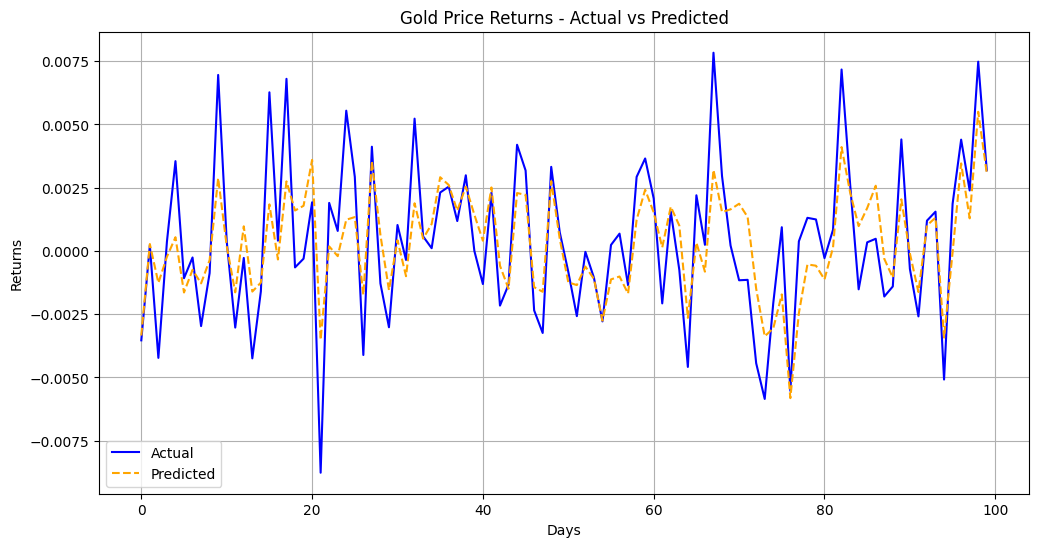

In [56]:
plt.figure(figsize=(12, 6))

plt.plot(y_test.values[:100], label='Actual', color='blue')

plt.plot(
    predictions[:100],
    label='Predicted',
    color='orange',
    linestyle='--'
)

plt.title('Gold Price Returns - Actual vs Predicted')

plt.xlabel('Days')

plt.ylabel('Returns')

plt.legend()

plt.grid(True)

plt.show()